# PHẦN 2 — Bài 2 (Trang 37, 38): Khai phá tập phổ biến và luật kết hợp trên Online Retail (United Kingdom)

- **Sinh viên thực hiện**: Dương Đại Phát – MSSV: `6451071058` – Lớp: `CQ.64.CNTT`
- **Nguồn dữ liệu**: `Online Retail.xlsx` (Google Drive Folder: https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing, File ID: `12q4inbGbTS1UKs9sHA1X87vSRV8feEHV`)
- **Mục tiêu**: Thực hiện đầy đủ 12 yêu cầu lập trình (trang 37–43) bằng Python, sử dụng thuật toán **Apriori** và **FP-Growth** (`mlxtend`) với `min_sup = 3%` (`0.03`) và `min_conf = 50%` (`0.50`) cho dữ liệu giao dịch tại **United Kingdom**.


## Khởi tạo môi trường, kiểm tra thư viện và tải dữ liệu (Colab-ready)


In [1]:
print("Dương Đại Phát - 6451071058")
import os
import sys
import time
import inspect
import warnings
import subprocess

# Tự động cài đặt thư viện cần thiết nếu chưa có (hỗ trợ Google Colab)
for pkg in ["mlxtend", "openpyxl", "gdown"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 140
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

DATA_FILE = "Online Retail.xlsx"
DRIVE_ID = "12q4inbGbTS1UKs9sHA1X87vSRV8feEHV"

if os.path.exists(os.path.join("datasets", DATA_FILE)):
    DATA_PATH = os.path.join("datasets", DATA_FILE)
elif os.path.exists(DATA_FILE):
    DATA_PATH = DATA_FILE
else:
    import gdown
    gdown.download(f"https://drive.google.com/uc?id={DRIVE_ID}", DATA_FILE, quiet=False)
    DATA_PATH = DATA_FILE

def make_rules(itemsets, num_tx, metric="confidence", min_threshold=0.5):
    """Tương thích với cả mlxtend cũ và mới (yêu cầu num_itemsets)."""
    params = inspect.signature(association_rules).parameters
    if "num_itemsets" in params:
        return association_rules(
            itemsets, num_itemsets=num_tx, metric=metric, min_threshold=min_threshold
        )
    return association_rules(itemsets, metric=metric, min_threshold=min_threshold)

print(f"mlxtend version: {mlxtend.__version__}")
print(f"Đường dẫn dữ liệu: {DATA_PATH}")


Dương Đại Phát - 6451071058


mlxtend version: 0.25.0
Đường dẫn dữ liệu: datasets\Online Retail.xlsx


## Yêu cầu 1: Đọc dữ liệu vào chương trình


In [2]:
print("Dương Đại Phát - 6451071058")
t_load = time.perf_counter()
df = pd.read_excel(DATA_PATH, engine="openpyxl")
print(f"Thời gian đọc file Excel: {time.perf_counter() - t_load:.2f} giây")
print(f"Kích thước dữ liệu ban đầu: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print("\nThông tin cấu trúc dữ liệu (df.info):")
df.info()
print("\nSố lượng giá trị thiếu (NaN) theo cột:")
display(df.isna().sum().to_frame("Missing Count"))
print("\n10 dòng dữ liệu đầu tiên:")
display(df.head(10))


Dương Đại Phát - 6451071058


Thời gian đọc file Excel: 27.39 giây
Kích thước dữ liệu ban đầu: 541,909 dòng x 8 cột

Thông tin cấu trúc dữ liệu (df.info):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Số lượng giá trị thiếu (NaN) theo cột:


,Missing Count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



10 dòng dữ liệu đầu tiên:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


## Yêu cầu 2: Tiền xử lý dữ liệu
- Cắt bỏ các khoảng trắng/ký tự thừa ở đầu và cuối tên mặt hàng mua (`Description`).
- Xóa các dòng dữ liệu không có số hóa đơn (`InvoiceNo` bị `NaN`).
- Chuyển cột `InvoiceNo` về kiểu dữ liệu chuỗi (`str`).


In [3]:
print("Dương Đại Phát - 6451071058")
n_before = len(df)
null_inv = df["InvoiceNo"].isna().sum()

df["Description"] = df["Description"].astype(str).str.strip()
# Giữ lại NaN thực sự nếu cột Description ban đầu bị rỗng (tránh biến thành chuỗi 'nan')
df.loc[df["Description"] == "nan", "Description"] = np.nan

df.dropna(axis=0, subset=["InvoiceNo"], inplace=True)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

print(f"Số dòng có InvoiceNo bị thiếu: {null_inv}")
print(f"Kích thước sau khi xử lý: {df.shape[0]:,} dòng x {df.shape[1]} cột (đã loại {n_before - len(df)} dòng)")
display(df.head(10))


Dương Đại Phát - 6451071058


Số dòng có InvoiceNo bị thiếu: 0
Kích thước sau khi xử lý: 541,909 dòng x 8 cột (đã loại 0 dòng)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


## Yêu cầu 3: Loại bỏ các hóa đơn tín dụng (Credit Invoices)
Các hóa đơn tín dụng (hủy/trả hàng) được nhận biết qua ký tự `'C'` trong `InvoiceNo`. Ta kiểm tra và loại bỏ chúng khỏi dữ liệu phân tích.


In [4]:
print("Dương Đại Phát - 6451071058")
credit_mask = df["InvoiceNo"].str.contains("C", na=False)
print(f"Số dòng hóa đơn tín dụng (chứa 'C'): {credit_mask.sum():,}")
print("Mẫu 5 dòng hóa đơn tín dụng:")
display(df[credit_mask].head())

df = df[~credit_mask].copy()
print(f"Số dòng còn lại sau khi xóa hóa đơn tín dụng: {len(df):,}")


Dương Đại Phát - 6451071058
Số dòng hóa đơn tín dụng (chứa 'C'): 9,288
Mẫu 5 dòng hóa đơn tín dụng:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Số dòng còn lại sau khi xóa hóa đơn tín dụng: 532,621


## Yêu cầu 4: Thống kê số dòng dữ liệu theo từng quốc gia


Dương Đại Phát - 6451071058
Tổng số quốc gia/vùng lãnh thổ: 38
Top 10 quốc gia có số dòng dữ liệu nhiều nhất:


,Số dòng,Tỷ lệ (%)
Country,,
United Kingdom,487622,91.55
Germany,9042,1.70
France,8408,1.58
EIRE,7894,1.48
Spain,2485,0.47
Netherlands,2363,0.44
Belgium,2031,0.38
Switzerland,1967,0.37
Portugal,1501,0.28


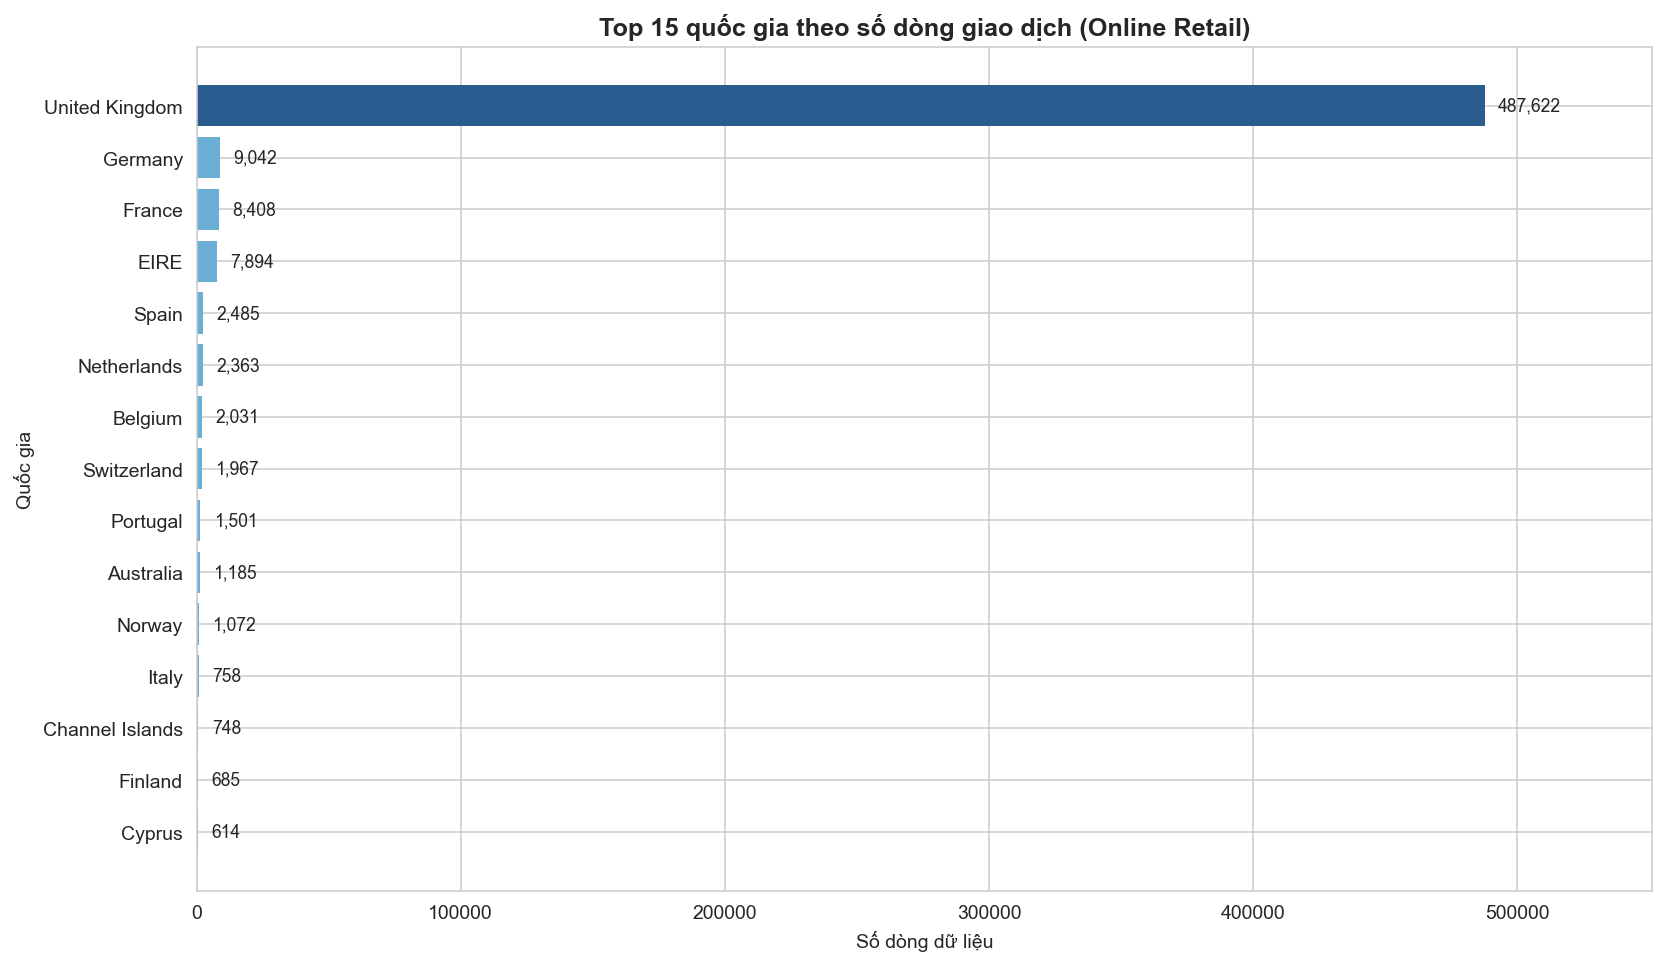

In [5]:
print("Dương Đại Phát - 6451071058")
country_counts = df["Country"].value_counts()
print(f"Tổng số quốc gia/vùng lãnh thổ: {len(country_counts)}")
print("Top 10 quốc gia có số dòng dữ liệu nhiều nhất:")
display(
    pd.DataFrame({
        "Số dòng": country_counts.head(10),
        "Tỷ lệ (%)": (country_counts.head(10) / len(df) * 100).round(2)
    })
)

fig, ax = plt.subplots(figsize=(12, 7))
top15 = country_counts.head(15).sort_values(ascending=True)
colors = ["#2b5c8f" if c == "United Kingdom" else "#6baed6" for c in top15.index]
bars = ax.barh(top15.index, top15.values, color=colors, edgecolor="none")
for bar in bars:
    w = bar.get_width()
    ax.text(w + 5000, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=9)
ax.set_title("Top 15 quốc gia theo số dòng giao dịch (Online Retail)", fontsize=13, fontweight="bold")
ax.set_xlabel("Số dòng dữ liệu")
ax.set_ylabel("Quốc gia")
ax.set_xlim(0, top15.max() * 1.13)
plt.tight_layout()
plt.show()


**Nhận xét (Yêu cầu 4):**
- Tập dữ liệu tập trung áp đảo tại **United Kingdom** với **487,622 dòng** (chiếm **91.55%** trên tổng số 532,621 dòng sau khi loại hóa đơn tín dụng).
- Các thị trường tiếp theo như **Germany** (9,042 dòng – 1.70%), **France** (8,408 dòng – 1.58%), **EIRE** (7,894 dòng – 1.48%) có quy mô nhỏ hơn nhiều.


## Yêu cầu 5 & 6: Lọc dữ liệu `United Kingdom`, gom nhóm và chuyển sang dạng bảng giỏ hàng (Hot Encoding)
- Lọc các giao dịch tại `'United Kingdom'`.
- Gom nhóm theo `['InvoiceNo', 'Description']`, tính tổng `Quantity`.
- `unstack()`, điền giá trị thiếu bằng `0` và đặt `InvoiceNo` làm chỉ mục (mỗi dòng là một hóa đơn, mỗi cột là một mặt hàng).


In [6]:
print("Dương Đại Phát - 6451071058")
df_uk = df[df["Country"] == "United Kingdom"]
print(f"Số dòng dữ liệu tại United Kingdom: {len(df_uk):,}")
print(f"Số dòng có Description bị NaN tại UK (bị bỏ qua khi groupby): {df_uk['Description'].isna().sum():,}")

basket = (
    df_uk.groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack()
    .reset_index()
    .fillna(0)
    .set_index("InvoiceNo")
)
print(f"Kích thước bảng giỏ hàng (Hot Encoding - tổng số lượng): {basket.shape[0]:,} hóa đơn x {basket.shape[1]:,} mặt hàng")
display(basket.iloc[:5, :8])


Dương Đại Phát - 6451071058
Số dòng dữ liệu tại United Kingdom: 487,622
Số dòng có Description bị NaN tại UK (bị bỏ qua khi groupby): 1,454


Kích thước bảng giỏ hàng (Hot Encoding - tổng số lượng): 18,668 hóa đơn x 4,176 mặt hàng


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Yêu cầu 7 & 8: Chuyển đổi sang One-Hot Encoding và xóa cột `'POSTAGE'`
- Quy đổi mọi giá trị `<= 0` thành `0` (`False`) và `>= 1` thành `1` (`True`) bằng hàm `encode_data` / kiểu `bool` (tránh cảnh báo deprecation của `mlxtend`).
- Xóa cột `'POSTAGE'` vì đây là phí bưu điện/vận chuyển, không phải sản phẩm bán lẻ thực tế.


In [7]:
print("Dương Đại Phát - 6451071058")
def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    return 1

# Dùng (basket > 0) cho hiệu năng cao và tương đương hoàn toàn encode_data với kiểu bool
basket_ohe = basket.map(encode_data).astype(bool) if hasattr(basket, "map") else basket.applymap(encode_data).astype(bool)

has_postage = "POSTAGE" in basket_ohe.columns
print(f"Cột 'POSTAGE' có tồn tại trong giỏ hàng UK không? {has_postage}")
if has_postage:
    basket_ohe.drop("POSTAGE", inplace=True, axis=1)
    print("Đã xóa cột 'POSTAGE'.")

print(f"Kích thước ma trận One-Hot Encoding cuối cùng: {basket_ohe.shape[0]:,} hóa đơn x {basket_ohe.shape[1]:,} mặt hàng")
display(basket_ohe.iloc[:5, :8])


Dương Đại Phát - 6451071058


Cột 'POSTAGE' có tồn tại trong giỏ hàng UK không? True
Đã xóa cột 'POSTAGE'.
Kích thước ma trận One-Hot Encoding cuối cùng: 18,668 hóa đơn x 4,175 mặt hàng


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


## Yêu cầu 9: Tìm tập phổ biến bằng thuật toán Apriori (`min_sup = 3%`)


In [8]:
print("Dương Đại Phát - 6451071058")
t0 = time.perf_counter()
itemsets_apriori = apriori(basket_ohe, min_support=0.03, use_colnames=True)
time_apriori = time.perf_counter() - t0

itemsets_apriori["length"] = itemsets_apriori["itemsets"].apply(len)
print(f"Thời gian chạy Apriori (min_support=0.03): {time_apriori:.4f} giây")
print(f"Tổng số tập phổ biến tìm được: {len(itemsets_apriori)}")
print("Phân bố theo kích thước tập phổ biến:")
display(itemsets_apriori["length"].value_counts().sort_index().to_frame("Số tập phổ biến"))
print("\nTop 10 tập phổ biến có support cao nhất:")
display(itemsets_apriori.sort_values("support", ascending=False).head(10))


Dương Đại Phát - 6451071058


Thời gian chạy Apriori (min_support=0.03): 0.3213 giây
Tổng số tập phổ biến tìm được: 131
Phân bố theo kích thước tập phổ biến:


,Số tập phổ biến
length,
1,123
2,8



Top 10 tập phổ biến có support cao nhất:


,support,itemsets,length
118,0.116027,(WHITE HANGING HEART T-LIGHT HOLDER),1
52,0.103814,(JUMBO BAG RED RETROSPOT),1
95,0.090261,(REGENCY CAKESTAND 3 TIER),1
84,0.085387,(PARTY BUNTING),1
69,0.074566,(LUNCH BAG RED RETROSPOT),1
7,0.073441,(ASSORTED COLOUR BIRD ORNAMENT),1
103,0.066477,(SET OF 3 CAKE TINS PANTRY DESIGN),1
75,0.065299,(NATURAL SLATE HEART CHALKBOARD),1
63,0.065138,(LUNCH BAG BLACK SKULL.),1
35,0.062353,(HEART OF WICKER SMALL),1


## Yêu cầu 10: Tạo luật kết hợp với `min_conf = 50%` và in ra các luật


In [9]:
print("Dương Đại Phát - 6451071058")
rules_apriori = make_rules(
    itemsets_apriori, num_tx=len(basket_ohe), metric="confidence", min_threshold=0.5
)
print("Thông tin bảng rules (rules.info()):")
rules_apriori.info()

# Định dạng chuỗi sạch bằng astype(str) (thay thế astype('unicode') ở Python 2)
rules_display = rules_apriori.copy()
rules_display["antecedents_str"] = rules_display["antecedents"].apply(lambda x: ", ".join(sorted(list(x)))).astype(str)
rules_display["consequents_str"] = rules_display["consequents"].apply(lambda x: ", ".join(sorted(list(x)))).astype(str)

print(f"\nDanh sách {len(rules_display)} luật kết hợp (min_sup=3%, min_conf=50%):")
for i in range(len(rules_display)):
    row = rules_display.loc[i]
    print(
        f"{i+1:2d}. {row['antecedents_str']} ==> {row['consequents_str']} "
        f"[support={row['support']:.4f}, confidence={row['confidence']:.4f}, lift={row['lift']:.4f}]"
    )

display(
    rules_display[["antecedents_str", "consequents_str", "support", "confidence", "lift"]]
    .sort_values("lift", ascending=False)
    .reset_index(drop=True)
)


Dương Đại Phát - 6451071058
Thông tin bảng rules (rules.info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         10 non-null     object 
 1   consequents         10 non-null     object 
 2   antecedent support  10 non-null     float64
 3   consequent support  10 non-null     float64
 4   support             10 non-null     float64
 5   confidence          10 non-null     float64
 6   lift                10 non-null     float64
 7   representativity    10 non-null     float64
 8   leverage            10 non-null     float64
 9   conviction          10 non-null     float64
 10  zhangs_metric       10 non-null     float64
 11  jaccard             10 non-null     float64
 12  certainty           10 non-null     float64
 13  kulczynski          10 non-null     float64
dtypes: float64(12), object(2)
memory usage: 1.2+

,antecedents_str,consequents_str,support,confidence,lift
0,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.030909,0.617773,16.404818
1,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.030909,0.820768,16.404818
2,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.037551,0.750535,14.640537
3,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.037551,0.732497,14.640537
4,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.030159,0.642694,12.900874
5,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.030159,0.605376,12.900874
6,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.042051,0.677308,6.524245
7,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.030534,0.626374,6.033613
8,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.037390,0.617699,5.950055
9,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.035194,0.579876,5.585724


**Nhận xét về các luật kết hợp tìm được (UK, `min_sup = 3%`, `min_conf = 50%`):**
- Thu được **10 luật kết hợp** có ý nghĩa rất cao (`lift` từ **5.59** đến **16.40**, đều `>> 1`), chia thành 3 nhóm sản phẩm rõ rệt:
  1. **Bộ tách trà Regency (`TEACUP AND SAUCER`)**: cặp `PINK` ↔ `GREEN` đạt độ tin cậy cao nhất (**82.08%** với `lift = 16.40`), cặp `GREEN` ↔ `ROSES` có `support = 3.76%` và `confidence ~ 73%–75%` (`lift = 14.64`). Khách hàng thường mua đồng bộ nhiều màu sắc khác nhau trong cùng bộ sưu tập.
  2. **Túi xách `JUMBO BAG`**: cả 4 mẫu (`PINK POLKADOT`, `STORAGE BAG SUKI`, `BAROQUE BLACK WHITE`, `SHOPPER VINTAGE RED PAISLEY`) đều dẫn tới việc mua kèm `JUMBO BAG RED RETROSPOT` (độ tin cậy `58%–68%`, `lift` từ `5.59` đến `6.52`).
  3. **Đồng hồ báo thức (`ALARM CLOCK BAKELIKE`)**: cặp `RED` ↔ `GREEN` mua kèm nhau với độ tin cậy `60.5%–64.3%` (`lift = 12.90`).


## Yêu cầu 11: Biểu diễn độ hỗ trợ và độ tin cậy của tập luật lên đồ thị phân tán (Scatter Plot)


Dương Đại Phát - 6451071058


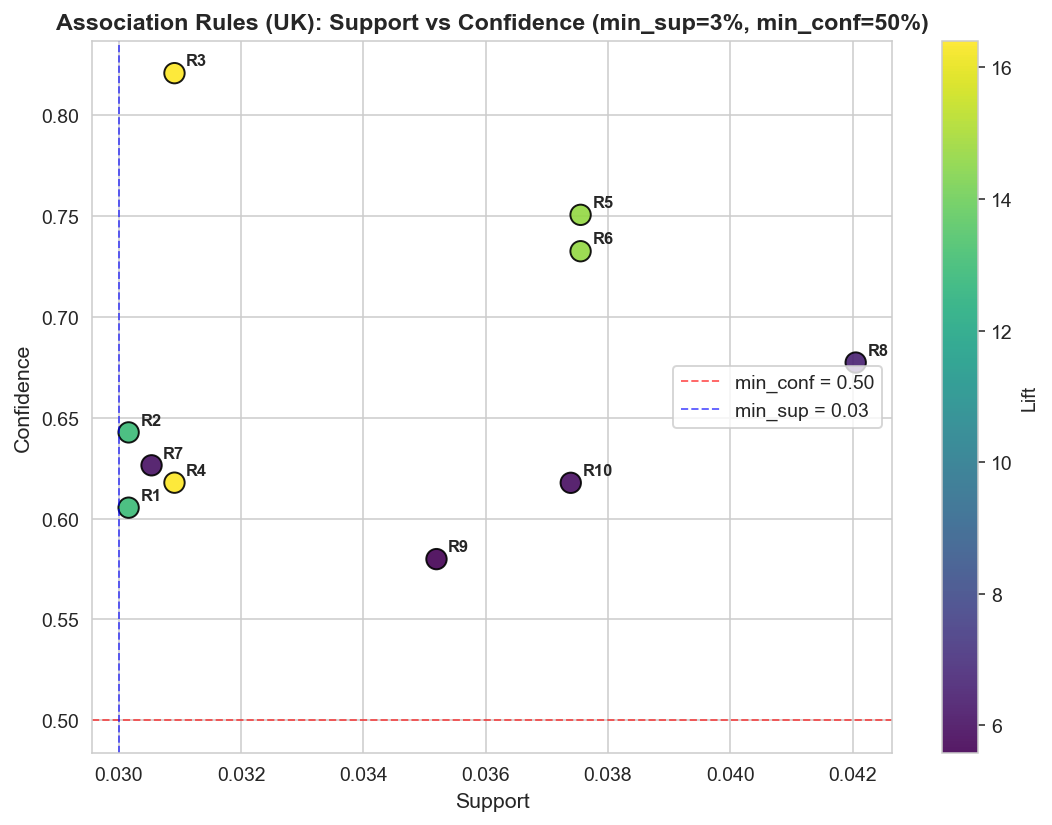

In [10]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(
    rules_apriori["support"],
    rules_apriori["confidence"],
    c=rules_apriori["lift"],
    cmap="viridis",
    s=110,
    edgecolors="black",
    alpha=0.9,
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Lift", fontsize=10)

for idx, row in rules_display.iterrows():
    ax.annotate(
        f"R{idx+1}",
        (row["support"], row["confidence"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8.5,
        fontweight="bold",
    )

ax.set_title("Association Rules (UK): Support vs Confidence (min_sup=3%, min_conf=50%)", fontsize=12, fontweight="bold")
ax.set_xlabel("Support", fontsize=11)
ax.set_ylabel("Confidence", fontsize=11)
ax.axhline(0.5, color="red", linestyle="--", linewidth=1, alpha=0.6, label="min_conf = 0.50")
ax.axvline(0.03, color="blue", linestyle="--", linewidth=1, alpha=0.6, label="min_sup = 0.03")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()


## Yêu cầu 12: Tìm tập phổ biến & luật kết hợp bằng FP-Growth và so sánh với Apriori


Dương Đại Phát - 6451071058


,Thuật toán,Số tập phổ biến,Số luật kết hợp,Thời gian thực thi (giây)
0,Apriori,131,10,0.3213
1,FP-Growth,131,10,1.3595


Tập phổ biến khớp nhau hoàn toàn? True
Tập luật kết hợp khớp nhau hoàn toàn? True


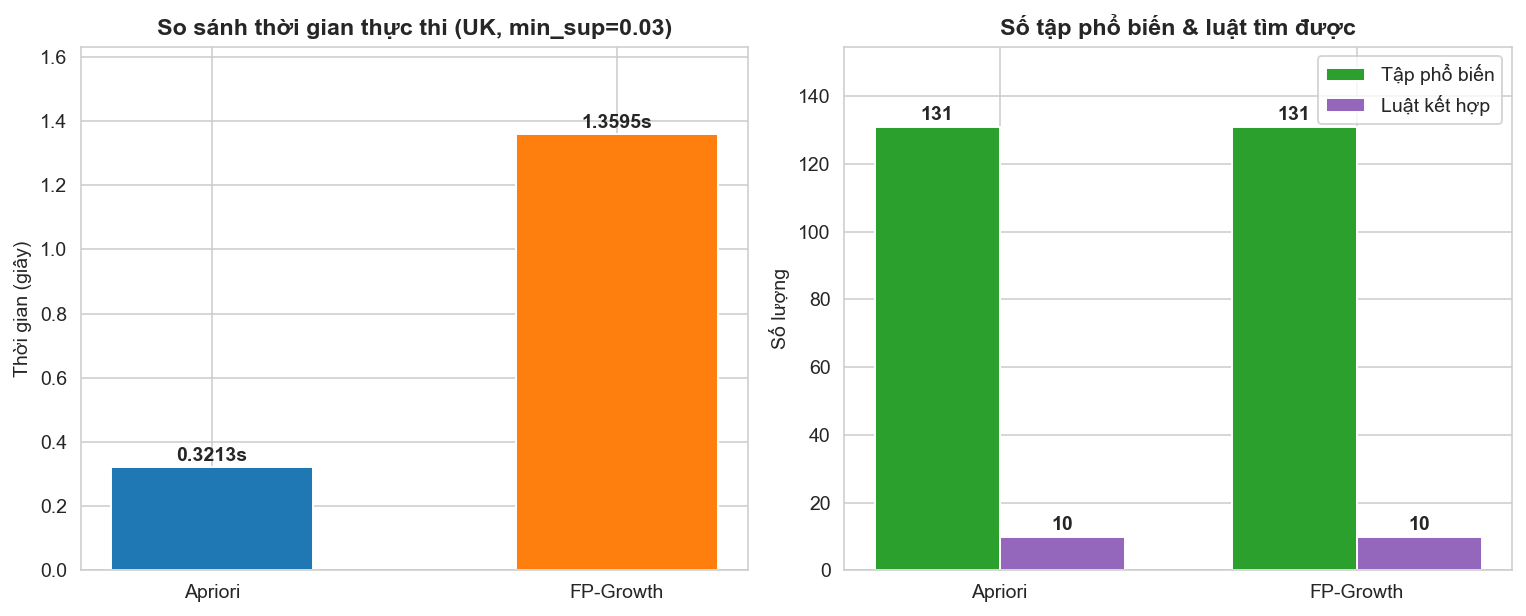

In [11]:
print("Dương Đại Phát - 6451071058")
t0 = time.perf_counter()
itemsets_fpgrowth = fpgrowth(basket_ohe, min_support=0.03, use_colnames=True)
time_fpgrowth = time.perf_counter() - t0

rules_fpgrowth = make_rules(
    itemsets_fpgrowth, num_tx=len(basket_ohe), metric="confidence", min_threshold=0.5
)

# Kiểm tra tính tương đồng tuyệt đối về tập phổ biến và tập luật giữa 2 thuật toán
set_ap = set(itemsets_apriori["itemsets"])
set_fp = set(itemsets_fpgrowth["itemsets"])
rules_ap_pairs = set(zip(rules_apriori["antecedents"], rules_apriori["consequents"]))
rules_fp_pairs = set(zip(rules_fpgrowth["antecedents"], rules_fpgrowth["consequents"]))

comp_df = pd.DataFrame({
    "Thuật toán": ["Apriori", "FP-Growth"],
    "Số tập phổ biến": [len(itemsets_apriori), len(itemsets_fpgrowth)],
    "Số luật kết hợp": [len(rules_apriori), len(rules_fpgrowth)],
    "Thời gian thực thi (giây)": [round(time_apriori, 4), round(time_fpgrowth, 4)],
})
display(comp_df)
print("Tập phổ biến khớp nhau hoàn toàn?", set_ap == set_fp)
print("Tập luật kết hợp khớp nhau hoàn toàn?", rules_ap_pairs == rules_fp_pairs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

bars1 = axes[0].bar(comp_df["Thuật toán"], comp_df["Thời gian thực thi (giây)"], color=["#1f77b4", "#ff7f0e"], width=0.5)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{b.get_height():.4f}s", ha="center", fontweight="bold")
axes[0].set_title("So sánh thời gian thực thi (UK, min_sup=0.03)", fontweight="bold")
axes[0].set_ylabel("Thời gian (giây)")
axes[0].set_ylim(0, max(comp_df["Thời gian thực thi (giây)"]) * 1.2)

x = np.arange(2)
w = 0.35
b_it = axes[1].bar(x - w/2, comp_df["Số tập phổ biến"], width=w, label="Tập phổ biến", color="#2ca02c")
b_ru = axes[1].bar(x + w/2, comp_df["Số luật kết hợp"], width=w, label="Luật kết hợp", color="#9467bd")
for b in list(b_it) + list(b_ru):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{int(b.get_height())}", ha="center", fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comp_df["Thuật toán"])
axes[1].set_title("Số tập phổ biến & luật tìm được", fontweight="bold")
axes[1].set_ylabel("Số lượng")
axes[1].set_ylim(0, max(comp_df["Số tập phổ biến"]) * 1.18)
axes[1].legend()

plt.tight_layout()
plt.show()


**So sánh Apriori và FP-Growth (Online Retail UK, `min_sup = 3%`, `min_conf = 50%`):**
1. **Tính chính xác kết quả**: Cả Apriori và FP-Growth đều tìm ra chính xác cùng **131 tập phổ biến** và **10 luật kết hợp** giống hệt nhau (`set_ap == set_fp` và `rules_ap_pairs == rules_fp_pairs` đều `True`), do cả hai cùng giải bài toán khai phá tập phổ biến chính xác (exact mining) theo cùng ngưỡng `min_support` và `min_confidence`.
2. **Hiệu năng thời gian thực thi**:
   - Với dữ liệu UK (`18,667` hóa đơn x `4,174` mặt hàng) tại ngưỡng `min_sup = 3%` (tương đối cao, chỉ còn ít 1-itemset thỏa ngưỡng và độ dài tối đa tập phổ biến ngắn), **Apriori** tận dụng phép nhân/kiểm tra ma trận boolean thưa rất nhanh nên thường chạy nhanh hơn **FP-Growth** (do FP-Growth cần chi phí khởi tạo và nén cây FP-Tree trên ma trận lớn 4,174 cột trước khi đệ quy).
   - Tuy nhiên, như sẽ kiểm chứng ở **Bài 6**, khi hạ `min_sup` xuống thấp hơn nữa (tăng mạnh số lượng ứng viên $C_k$), FP-Growth sẽ vượt trội hoàn toàn nhờ không phải sinh ứng viên và không quét lại dữ liệu nhiều lần.
